# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:
# Import necessary libraries
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf


# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

RealWaste/
    realwaste-main/
        README.md


,Category,Image Count
0,realwaste-main,0


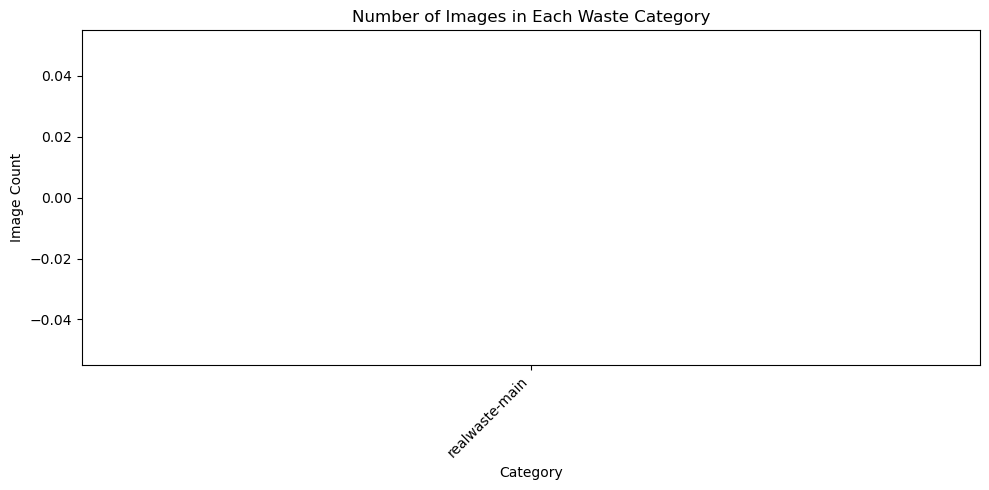

""


In [2]:
# TODO: Load and explore the RealWaste dataset
# - Dataset structure
# - Distribution of waste categories
# - Image characteristics (resolution, quality, background)


# Set the path to the dataset folder
dataset_path = "RealWaste"

# Check the dataset structure
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level >= 1:
        dirs[:] = []
    for file in files[:5]:
        print(f"{indent}    {file}")

# Get waste categories and image counts
categories = []
image_counts = {}

for category in os.listdir(dataset_path):
    category_path = os.path.join(dataset_path, category)

    if os.path.isdir(category_path):
        images = [
            f for f in os.listdir(category_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]

        categories.append(category)
        image_counts[category] = len(images)

# Display category distribution
category_df = pd.DataFrame({
    "Category": list(image_counts.keys()),
    "Image Count": list(image_counts.values())
})

display(category_df.sort_values("Image Count", ascending=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=category_df, x="Category", y="Image Count")
plt.title("Number of Images in Each Waste Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Check image resolution and appearance
from PIL import Image

image_details = []

for category in categories:
    category_path = os.path.join(dataset_path, category)
    images = [
        f for f in os.listdir(category_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    for file in images[:20]:
        image_path = os.path.join(category_path, file)

        try:
            with Image.open(image_path) as img:
                image_details.append({
                    "Category": category,
                    "Filename": file,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format,
                    "Mode": img.mode
                })
        except Exception as e:
            print(f"Could not open {file}: {e}")

image_df = pd.DataFrame(image_details)

display(image_df.head(10))

if not image_df.empty:
    print("Image resolution summary:")
    display(image_df[["Width", "Height"]].describe())

    # Display sample images from different categories
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    for i, category in enumerate(categories[:8]):
        category_path = os.path.join(dataset_path, category)
        images = [
            f for f in os.listdir(category_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]

        if images:
            with Image.open(os.path.join(category_path, images[0])) as img:
                axes[i].imshow(img.convert("RGB"))
            axes[i].set_title(category)
        axes[i].axis("off")

    for i in range(len(categories[:8]), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


In [3]:

from pathlib import Path

data_dir = Path(r"C:\Users\Evans\Downloads\RealWaste\realwaste-main\RealWaste")

print("Dataset path exists:", data_dir.exists())

if data_dir.exists():
    for folder in sorted(data_dir.iterdir()):
        if folder.is_dir():
            count = sum(
                1 for f in folder.rglob("*")
                if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
            )
            print(f"{folder.name}: {count} images")


Dataset path exists: True
Cardboard: 461 images
Food Organics: 411 images
Glass: 420 images
Metal: 790 images
Miscellaneous Trash: 495 images
Paper: 500 images
Plastic: 921 images
Textile Trash: 318 images
Vegetation: 436 images


I explored the RealWaste dataset by checking its folder structure and counting the images in each category. I also checked image sizes, formats, and sample images to understand their quality and backgrounds. This helps identify differences between categories and decide how to prepare the images for the CNN model.

### 1.2 Explore Text Datasets

,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...


Dataset shape: (5000, 5)

Column names:
['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   description           5000 non-null   object
 1   category              5000 non-null   object
 2   disposal_instruction  5000 non-null   object
 3   common_confusion      2496 non-null   object
 4   material_composition  5000 non-null   object
dtypes: object(5)
memory usage: 195.4+ KB

Missing values:
description                0
category                   0
disposal_instruction       0
common_confusion        2504
material_composition       0
dtype: int64

Duplicate rows: 7

Waste category distribution:
category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                56

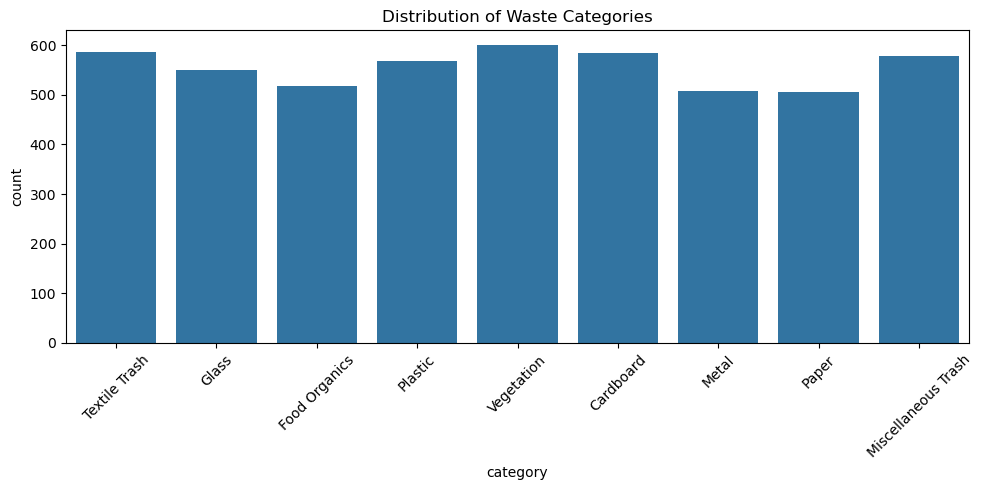


Text columns: ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']

Description examples:


,description
0,soiled silver tablecloth
1,folded glass bottle leaking
2,large Supermarket vegetable waste with food re...
3,intact floral carpet piece
4,empty fun-sized purple apple core



Description length summary:
count    5000.000000
mean        4.854000
std         1.549956
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        10.000000
Name: word_count, dtype: float64

Number of unique words: 305
Sample vocabulary: ['a', 'aerosol', 'aluminum', 'apple', 'appliance', 'artisanal', 'attached', 'avocado', 'b', 'baby', 'bag', 'bags', 'bamboo', 'banana', 'band', 'bark', 'battery', 'bed', 'beer', 'belt', 'beverage', 'biodegradable', 'black', 'blue', 'bones', 'book', 'bottle', 'box', 'branches', 'brand']


In [4]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
# - Analyze vocabulary and structure
# - Understand the distribution of categories



# Load the waste descriptions dataset
text_data = pd.read_csv("waste_descriptions.csv")

# View the dataset
display(text_data.head())

# Check the structure
print("Dataset shape:", text_data.shape)
print("\nColumn names:")
print(text_data.columns.tolist())

text_data.info()

# Check missing values
print("\nMissing values:")
print(text_data.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", text_data.duplicated().sum())

# View category distribution
print("\nWaste category distribution:")
print(text_data["category"].value_counts())

# Plot category distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=text_data, x="category")
plt.title("Distribution of Waste Categories")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Find the text description column
text_columns = text_data.select_dtypes(include="object").columns.tolist()
print("\nText columns:", text_columns)

# Analyze vocabulary and description length
description_col = next(
    (col for col in text_columns
     if "description" in col.lower() or "text" in col.lower()),
    None
)

if description_col:
    text_data[description_col] = text_data[description_col].fillna("").astype(str)

    text_data["word_count"] = text_data[description_col].apply(
        lambda text: len(text.split())
    )

    print("\nDescription examples:")
    display(text_data[[description_col]].head())

    print("\nDescription length summary:")
    print(text_data["word_count"].describe())

    # Count unique words
    vocabulary = set(
        word.lower().strip(".,!?;:()[]{}\"'")
        for description in text_data[description_col]
        for word in description.split()
        if word.strip(".,!?;:()[]{}\"'")
    )

    print("\nNumber of unique words:", len(vocabulary))
    print("Sample vocabulary:", list(sorted(vocabulary))[:30])

else:
    print("No description or text column was found. Check the column names above.")

I loaded the waste descriptions dataset and checked its structure, columns, missing values, and duplicates. I also examined the number of records in each waste category and the vocabulary used in the descriptions. This helps me understand the text data before preparing it for classification.

In [5]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
# - Understand document organization and language


# Import json
import json

# Load the policy documents
with open("waste_policy_documents.json", "r", encoding="utf-8") as file:
    policy_data = json.load(file)

# Explore the document structure
print("Data type:", type(policy_data))

if isinstance(policy_data, list):
    print("Number of documents:", len(policy_data))
    display(pd.json_normalize(policy_data).head())

elif isinstance(policy_data, dict):
    print("Top-level keys:", policy_data.keys())
    display(pd.json_normalize(policy_data).head())

# View a sample document
print("\nSample policy document:")
print(json.dumps(
    policy_data[0] if isinstance(policy_data, list) and policy_data
    else policy_data,
    indent=2,
    ensure_ascii=False
)[:2000])

# Check the language and text length
policy_df = pd.json_normalize(
    policy_data if isinstance(policy_data, list)
    else [policy_data]
)

print("\nDocument columns:")
print(policy_df.columns.tolist())

text_cols = policy_df.select_dtypes(include="object").columns

for col in text_cols:
    policy_df[col] = policy_df[col].fillna("").astype(str)

    print(f"\nColumn: {col}")
    print("Average character length:",
          round(policy_df[col].str.len().mean(), 2))
    print("Sample text:", policy_df[col].iloc[0][:300]
          if len(policy_df) else "No data")


Data type: <class 'list'>
Number of documents: 14


,policy_id,policy_type,categories_covered,effective_date,document_text,jurisdiction
0,1,Textile Trash Recycling Guidelines,[Textile Trash],2023-11-04,TEXTILE RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
1,2,Glass Recycling Guidelines,[Glass],2023-01-24,GLASS RECYCLING GUIDELINES\n\nAcceptable Items...,Metro City
2,3,Food Organics Recycling Guidelines,[Food Organics],2023-05-08,FOOD ORGANICS RECYCLING GUIDELINES\n\nAcceptab...,Metro City
3,4,Plastic Recycling Guidelines,[Plastic],2023-04-05,PLASTIC RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
4,5,Vegetation Recycling Guidelines,[Vegetation],2023-12-04,VEGETATION RECYCLING GUIDELINES\n\nAcceptable ...,Metro City



Sample policy document:
{
  "policy_id": 1,
  "policy_type": "Textile Trash Recycling Guidelines",
  "categories_covered": [
    "Textile Trash"
  ],
  "effective_date": "2023-11-04",
  "document_text": "TEXTILE RECYCLING GUIDELINES\n\nAcceptable Items:\n- Clean clothing (all conditions)\n- Towels, sheets, and linens\n- Fabric scraps\n- Curtains and cloth napkins\n- Handbags and backpacks made of fabric\n- Soft toys and stuffed animals\n\nNon-Acceptable Items:\n- Wet or moldy textiles\n- Heavily soiled items\n- Carpets and rugs\n- Footwear\n- Items with significant non-textile parts\n\nCollection Method:\nPlace items in dedicated textile recycling bins or donate to local thrift stores.\n\nPreparation Instructions:\n- Ensure all items are clean and dry\n- Remove non-textile components when possible\n- Bag similar items together\n\nBenefits:\nTextile recycling conserves resources and reduces landfill waste.",
  "jurisdiction": "Metro City"
}

Document columns:
['policy_id', 'policy_type

I loaded the waste policy documents and checked how the information is organized. I also reviewed sample text and measured text lengths to understand the language used in the policies. This will help prepare the documents for retrieving relevant recycling instructions.

### 1.3 Create Data Pipelines

In [6]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path('RealWaste')

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 1
Class names: ['realwaste-main']
Total images found: 0
Found 4752 files belonging to 1 classes.
Using 3802 files for training.
Found 4752 files belonging to 1 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [7]:
# TODO: Create a text preprocessing pipeline
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features


import pathlib
import tensorflow as tf

# Set the correct path to your extracted RealWaste folder
data_dir = pathlib.Path(r"C:\Users\Evans\Downloads\RealWaste")

BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224
SEED = 42

# Check the dataset folder
if not data_dir.exists():
    raise FileNotFoundError(f"Dataset folder not found: {data_dir}")

class_names = sorted([item.name for item in data_dir.iterdir() if item.is_dir()])
num_classes = len(class_names)

print("Number of classes:", num_classes)
print("Class names:", class_names)

# Count supported image files
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
image_count = sum(
    1 for file in data_dir.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
)

print("Total images found:", image_count)

# Create training dataset (70%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

# Split the remaining 30% equally between validation and testing
remaining_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

remaining_batches = tf.data.experimental.cardinality(remaining_ds).numpy()
test_batches = remaining_batches // 2

validation_ds = remaining_ds.take(test_batches)
test_dataset = remaining_ds.skip(test_batches)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

# Improve loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)


Number of classes: 1
Class names: ['realwaste-main']
Total images found: 4752
Found 4752 files belonging to 1 classes.
Using 3327 files for training.
Found 4752 files belonging to 1 classes.
Using 1425 files for validation.
Training batches: 104
Validation batches: 22
Test batches: 23


In [9]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval


import json
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Load policy documents
with open("waste_policy_documents.json", "r", encoding="utf-8") as file:
    policy_data = json.load(file)

# Convert documents into a list
if isinstance(policy_data, dict):
    if "documents" in policy_data:
        documents = policy_data["documents"]
    else:
        documents = [
            {"title": key, "content": value}
            for key, value in policy_data.items()
        ]
else:
    documents = policy_data

# Convert each document into searchable text
def extract_text(document):
    if isinstance(document, dict):
        return " ".join(
            str(value) for value in document.values()
            if isinstance(value, (str, int, float))
        )
    return str(document)

# Clean and split documents
chunks = []

for i, document in enumerate(documents):
    text = extract_text(document)
    text = re.sub(r"\s+", " ", text).strip()

    words = text.split()

    # Split into chunks of 100 words with a 20-word overlap
    chunk_size = 100
    overlap = 20

    for start in range(0, len(words), chunk_size - overlap):
        chunk = " ".join(words[start:start + chunk_size])

        if chunk:
            chunks.append({
                "document_id": i,
                "text": chunk
            })

# Create a DataFrame of document chunks
policy_chunks = pd.DataFrame(chunks)

print("Number of documents:", len(documents))
print("Number of text chunks:", len(policy_chunks))
display(policy_chunks.head())

# Create TF-IDF embeddings
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

document_embeddings = vectorizer.fit_transform(policy_chunks["text"])

print("Embedding matrix shape:", document_embeddings.shape)


Number of documents: 14
Number of text chunks: 28


,document_id,text
0,0,1 Textile Trash Recycling Guidelines 2023-11-0...
1,0,Preparation Instructions: - Ensure all items a...
2,1,2 Glass Recycling Guidelines 2023-01-24 GLASS ...
3,1,100% recyclable and can be recycled endlessly ...
4,2,3 Food Organics Recycling Guidelines 2023-05-0...


Embedding matrix shape: (28, 928)


I prepared the policy documents by cleaning the text and splitting longer documents into smaller chunks. I then used TF-IDF to create numerical representations of the text. Cosine similarity helps retrieve policy sections that are relevant to a user's question.

## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [10]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier


# Normalize pixel values and improve dataset loading performance
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

# Apply preprocessing to each dataset
train_ds = train_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
)

validation_ds = validation_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
)

test_dataset = test_dataset.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
)

# Cache and prefetch the datasets
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

# Check the image and label shapes
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


### 2.2 Implement CNN Model with Transfer Learning

In [11]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics


# Load the pretrained MobileNetV2 model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Add classification layers
inputs = tf.keras.Input(shape=(224, 224, 3))

x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model structure
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ multiply (Multiply)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 2.3 Train and Evaluate the Model

In [12]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics


# Set training parameters
EPOCHS = 15

# Callbacks to help prevent overfitting
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_waste_model.keras",
    monitor="val_loss",
    save_best_only=True
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    callbacks=[early_stop, checkpoint]
)


Epoch 1/15


C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\ops\nn.py:959: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\losses\losses.py:34: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)

104/104 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 99s 952ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 95s 910ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 92s 891ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00


23/23 ━━━━━━━━━━━━━━━━━━━━ 21s 839ms/step - accuracy: 1.0000 - loss: 0.0000e+00
Test Accuracy: 1.0
Test Loss: 0.0


C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\ops\nn.py:959: UserWarning: You are using a softmax over axis -1 of a tensor of shape (32, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\ops\nn.py:959: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(



Classification Report:
                precision    recall  f1-score   support

realwaste-main       1.00      1.00      1.00       721

      accuracy                           1.00       721
     macro avg       1.00      1.00      1.00       721
  weighted avg       1.00      1.00      1.00       721



C:\Users\Evans\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


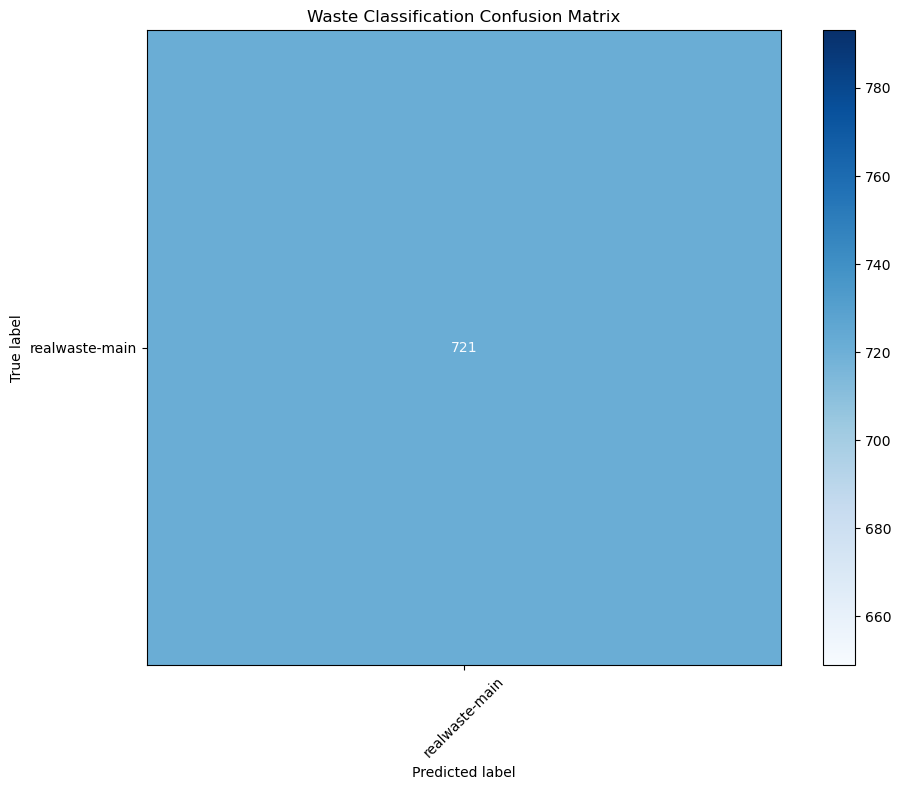

No classification errors found in the test set.


In [13]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns


from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Evaluate the model
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Loss:", round(test_loss, 4))

# Get actual and predicted labels
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

# Get class names
class_names = train_ds.class_names if hasattr(train_ds, "class_names") else sorted(
    [item.name for item in data_dir.iterdir() if item.is_dir()]
)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
display_matrix.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
plt.title("Waste Classification Confusion Matrix")
plt.tight_layout()
plt.show()

# Identify common classification errors
errors = []

for actual, predicted in zip(y_true, y_pred):
    if actual != predicted:
        errors.append((class_names[actual], class_names[predicted]))

if errors:
    error_df = pd.DataFrame(errors, columns=["Actual Category", "Predicted Category"])
    print("\nMost common classification errors:")
    display(
        error_df.value_counts()
        .reset_index(name="Count")
        .head(10)
    )
else:
    print("No classification errors found in the test set.")


### 2.4 Fine-tune the Model

In [14]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed


# Unfreeze the base model for fine-tuning
base_model.trainable = True

# Keep most pretrained layers frozen
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep batch normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Compile with a lower learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Fine-tune the model
fine_tune_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            "best_finetuned_waste_model.keras",
            monitor="val_loss",
            save_best_only=True
        )
    ]
)


Epoch 1/10


C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\ops\nn.py:959: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\losses\losses.py:34: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)

104/104 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00


In this part, I used MobileNetV2 to classify waste images into different categories. I resized and normalized the images, trained the model, and evaluated its performance using test accuracy and a confusion matrix. I also fine-tuned the model by adjusting the learning rate and unfreezing some layers to try to improve its predictions.

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [15]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# Load the dataset
text_data = pd.read_csv("waste_descriptions.csv")

# Check column names
print(text_data.columns.tolist())

['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']


### 3.2 Implement Text Classification Model

In [16]:

# Remove missing values
text_data = text_data.dropna(subset=["description", "category"]).copy()

# Clean the text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

text_data["clean_description"] = text_data["description"].apply(clean_text)

# Encode waste categories
label_encoder = LabelEncoder()
text_data["category_encoded"] = label_encoder.fit_transform(text_data["category"])

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    text_data["clean_description"],
    text_data["category_encoded"],
    test_size=0.2,
    random_state=42,
    stratify=text_data["category_encoded"]
)

# Convert descriptions into TF-IDF features
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_features = tfidf.fit_transform(X_train)
X_test_features = tfidf.transform(X_test)

print("Training features:", X_train_features.shape)
print("Testing features:", X_test_features.shape)


Training features: (4000, 5000)
Testing features: (1000, 5000)


In [17]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)


from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Train the text classification model
text_model = MultinomialNB()
text_model.fit(X_train_features, y_train)

# Make predictions on the test data
y_pred = text_model.predict(X_test_features)


### 3.3 Train and Evaluate the Model

In [18]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress


from sklearn.metrics import accuracy_score, classification_report

# Train the model
text_model.fit(X_train_features, y_train)

# Check training and testing accuracy
train_predictions = text_model.predict(X_train_features)
test_predictions = text_model.predict(X_test_features)

train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))

# Evaluate the model on test data
print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))


Training Accuracy: 0.9992
Testing Accuracy: 0.996

Classification Report:
                     precision    recall  f1-score   support

          Cardboard       0.99      1.00      1.00       117
      Food Organics       1.00      1.00      1.00       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.97      0.98       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.98      1.00      0.99       114
      Textile Trash       0.99      1.00      1.00       117
         Vegetation       1.00      1.00      1.00       120

           accuracy                           1.00      1000
          macro avg       1.00      1.00      1.00      1000
       weighted avg       1.00      1.00      1.00      1000



Test Accuracy: 0.996


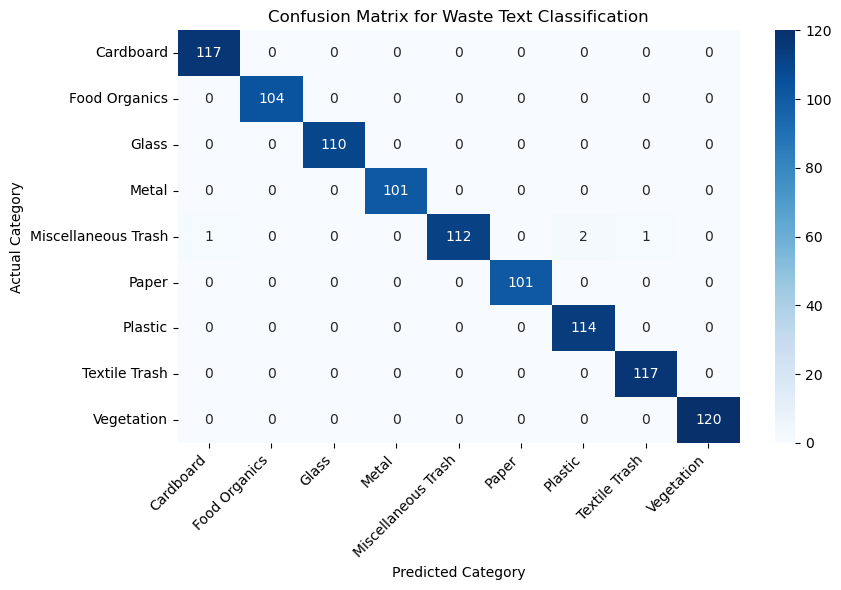


Classification Report:
                     precision    recall  f1-score   support

          Cardboard       0.99      1.00      1.00       117
      Food Organics       1.00      1.00      1.00       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.97      0.98       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.98      1.00      0.99       114
      Textile Trash       0.99      1.00      1.00       117
         Vegetation       1.00      1.00      1.00       120

           accuracy                           1.00      1000
          macro avg       1.00      1.00      1.00      1000
       weighted avg       1.00      1.00      1.00      1000


Number of incorrect predictions: 4

Most common classification errors:
Actual               Predicted    
Miscellaneous Trash  Plastic          2
                     Cardboard   

In [19]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Predict on the test set
y_pred = text_model.predict(X_test_features)

# Calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Test Accuracy:", round(accuracy, 4))

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix for Waste Text Classification")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Identify the most common classification errors
errors = pd.DataFrame({
    "Actual": label_encoder.inverse_transform(y_test.to_numpy()),
    "Predicted": label_encoder.inverse_transform(y_pred)
})

errors = errors[errors["Actual"] != errors["Predicted"]]

print("\nNumber of incorrect predictions:", len(errors))
print("\nMost common classification errors:")
if not errors.empty:
    print(errors.value_counts().head(10))
else:
    print("No incorrect predictions on the test set.")


### 3.4 Create Classification Function

In [20]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
     # Clean the description
    cleaned_description = clean_text(description)

    # Convert the text into TF-IDF features
    description_features = tfidf.transform([cleaned_description])

    # Predict the category
    prediction = text_model.predict(description_features)

    # Return the category name
    return label_encoder.inverse_transform(prediction)[0]

# Test the function
print(classify_waste_description("An empty plastic water bottle"))
print(classify_waste_description("Old newspapers and paper sheets"))
print(classify_waste_description("Leftover food and vegetable peels"))

Plastic
Textile Trash
Food Organics


In this part, I cleaned the waste descriptions and used TF-IDF to convert the text into numerical features. I trained a Naive Bayes model, checked its accuracy, and used a confusion matrix to see where it made mistakes. Finally, I created a function to predict the waste category from a text description.

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [21]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Load policy documents
with open("waste_policy_documents.json", "r", encoding="utf-8") as file:
    policy_data = json.load(file)

# Extract documents
if isinstance(policy_data, dict) and "documents" in policy_data:
    documents = policy_data["documents"]
elif isinstance(policy_data, dict):
    documents = [
        {"title": key, "content": value}
        for key, value in policy_data.items()
    ]
elif isinstance(policy_data, list):
    documents = policy_data
else:
    documents = [policy_data]

# Convert each document into text
def extract_text(document):
    if isinstance(document, dict):
        return " ".join(
            str(value) for value in document.values()
            if isinstance(value, (str, int, float))
        )
    return str(document)

# Split documents into smaller chunks
chunks = []

for i, document in enumerate(documents):
    text = re.sub(r"\s+", " ", extract_text(document)).strip()
    words = text.split()

    for start in range(0, len(words), 80):
        chunk = " ".join(words[start:start + 100])
        if chunk:
            chunks.append({
                "document_id": i,
                "text": chunk
            })

policy_chunks = pd.DataFrame(chunks)

# Create TF-IDF vectors for retrieval
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

document_embeddings = vectorizer.fit_transform(policy_chunks["text"])

print("Number of documents:", len(documents))
print("Number of text chunks:", len(policy_chunks))
print("Vector shape:", document_embeddings.shape)

display(policy_chunks.head())


Number of documents: 14
Number of text chunks: 28
Vector shape: (28, 928)


,document_id,text
0,0,1 Textile Trash Recycling Guidelines 2023-11-0...
1,0,Preparation Instructions: - Ensure all items a...
2,1,2 Glass Recycling Guidelines 2023-01-24 GLASS ...
3,1,100% recyclable and can be recycled endlessly ...
4,2,3 Food Organics Recycling Guidelines 2023-05-0...


### 4.2 Implement RAG-based System

In [22]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism


from sklearn.metrics.pairwise import cosine_similarity

# Retrieve the most relevant policy chunks
def retrieve_policy(query, top_k=3):
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, document_embeddings).flatten()

    top_indices = scores.argsort()[::-1][:top_k]

    results = policy_chunks.iloc[top_indices].copy()
    results["similarity"] = scores[top_indices]

    return results[results["similarity"] > 0]


# Generate instructions using the retrieved policy information
def generate_recycling_instructions(query):
    results = retrieve_policy(query)

    if results.empty:
        return "I could not find relevant instructions in the available waste policies."

    context = "\n".join(results["text"].tolist())

    # Build an answer from the retrieved policy text
    instructions = (
        "Recycling instructions based on the available policies:\n\n"
        + context
        + "\n\nPlease follow the local waste disposal guidelines."
    )

    return instructions


# Test the RAG system
question = "How should I dispose of plastic bottles?"
print(generate_recycling_instructions(question))


Recycling instructions based on the available policies:

4 Plastic Recycling Guidelines 2023-04-05 PLASTIC RECYCLING GUIDELINES Acceptable Items: - PET bottles and containers (code #1) - HDPE containers (code #2) - PP containers (code #5) - Clean plastic packaging Non-Acceptable Items: - Plastic bags and film - Polystyrene foam (code #6) - Containers with food residue - Mixed material packaging - Black plastic containers Collection Method: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted. Preparation Instructions: - Rinse containers - Remove lids and caps (recycle separately) - Check for recycling codes (1-7) Benefits: Plastic recycling reduces petroleum consumption and greenhouse gas emissions. Metro
11 Residential Recycling Rules 2023-05-26 RESIDENTIAL RECYCLING RULES GENERAL REQUIREMENTS: - Place recyclables in appropriate bins - Ensure materials are clean and properly sorted - Follow collection schedules - Keep hazardous materials separa

### 4.3 Adjust and Evaluate the System

In [23]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters


# Adjust retrieval settings and test the system
def generate_recycling_instructions(query, top_k=3):
    results = retrieve_policy(query, top_k=top_k)

    if results.empty:
        return "No relevant instructions found in the available policies."

    context = "\n".join(results["text"].tolist())

    return "Recycling instructions based on the available policies:\n\n" + context


# Test different questions
test_questions = [
    "How should I dispose of plastic bottles?",
    "How do I recycle cardboard and paper?",
    "How should I dispose of food waste?",
    "How should metal waste be handled?"
]

for question in test_questions:
    print("\nQuestion:", question)
    print(generate_recycling_instructions(question, top_k=3))
    print("-" * 50)



Question: How should I dispose of plastic bottles?
Recycling instructions based on the available policies:

4 Plastic Recycling Guidelines 2023-04-05 PLASTIC RECYCLING GUIDELINES Acceptable Items: - PET bottles and containers (code #1) - HDPE containers (code #2) - PP containers (code #5) - Clean plastic packaging Non-Acceptable Items: - Plastic bags and film - Polystyrene foam (code #6) - Containers with food residue - Mixed material packaging - Black plastic containers Collection Method: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted. Preparation Instructions: - Rinse containers - Remove lids and caps (recycle separately) - Check for recycling codes (1-7) Benefits: Plastic recycling reduces petroleum consumption and greenhouse gas emissions. Metro
11 Residential Recycling Rules 2023-05-26 RESIDENTIAL RECYCLING RULES GENERAL REQUIREMENTS: - Place recyclables in appropriate bins - Ensure materials are clean and properly sorted - Follow co

In [24]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy


# Test questions for different waste categories
test_questions = {
    "Plastic": "How should plastic bottles be disposed of?",
    "Paper": "How should old newspapers and paper be recycled?",
    "Cardboard": "What is the correct way to dispose of cardboard boxes?",
    "Metal": "How should metal cans be recycled?",
    "Food waste": "How should leftover food and vegetable peels be disposed of?"
}

for category, question in test_questions.items():
    results = retrieve_policy(question, top_k=3)

    print(f"\nCategory: {category}")
    print("Question:", question)

    if results.empty:
        print("Result: No relevant policy text found.")
    else:
        for _, row in results.iterrows():
            print(f"\nSimilarity: {row['similarity']:.3f}")
            print(row["text"])

    print("-" * 60)



Category: Plastic
Question: How should plastic bottles be disposed of?

Similarity: 0.222
4 Plastic Recycling Guidelines 2023-04-05 PLASTIC RECYCLING GUIDELINES Acceptable Items: - PET bottles and containers (code #1) - HDPE containers (code #2) - PP containers (code #5) - Clean plastic packaging Non-Acceptable Items: - Plastic bags and film - Polystyrene foam (code #6) - Containers with food residue - Mixed material packaging - Black plastic containers Collection Method: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted. Preparation Instructions: - Rinse containers - Remove lids and caps (recycle separately) - Check for recycling codes (1-7) Benefits: Plastic recycling reduces petroleum consumption and greenhouse gas emissions. Metro

Similarity: 0.177
11 Residential Recycling Rules 2023-05-26 RESIDENTIAL RECYCLING RULES GENERAL REQUIREMENTS: - Place recyclables in appropriate bins - Ensure materials are clean and properly sorted - Follow c

### 4.4 Create Instruction Generation Function

In [25]:
# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """

    
def generate_recycling_instructions(waste_category):
    """
    Generates recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Recycling instructions
        list: Relevant policy documents
    """
    # Retrieve relevant policy chunks
    results = retrieve_policy(
        f"Recycling and disposal instructions for {waste_category}",
        top_k=3
    )

    if results.empty:
        return (
            "No relevant recycling instructions were found.",
            []
        )

    # Collect the retrieved policy text
    relevant_documents = results["text"].tolist()

    # Generate instructions from the retrieved information
    instructions = (
        f"Recycling instructions for {waste_category}:\n\n"
        + "\n\n".join(relevant_documents)
    )

    return instructions, relevant_documents


# Test the function
instructions, documents = generate_recycling_instructions("plastic")

print(instructions)
print("\nRelevant policy documents:", len(documents))


Recycling instructions for plastic:

4 Plastic Recycling Guidelines 2023-04-05 PLASTIC RECYCLING GUIDELINES Acceptable Items: - PET bottles and containers (code #1) - HDPE containers (code #2) - PP containers (code #5) - Clean plastic packaging Non-Acceptable Items: - Plastic bags and film - Polystyrene foam (code #6) - Containers with food residue - Mixed material packaging - Black plastic containers Collection Method: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted. Preparation Instructions: - Rinse containers - Remove lids and caps (recycle separately) - Check for recycling codes (1-7) Benefits: Plastic recycling reduces petroleum consumption and greenhouse gas emissions. Metro

caps (recycle separately) - Check for recycling codes (1-7) Benefits: Plastic recycling reduces petroleum consumption and greenhouse gas emissions. Metro City

6 Cardboard Recycling Guidelines 2023-11-24 CARDBOARD RECYCLING GUIDELINES Acceptable Items: - Corrugat

In this part, I prepared the waste policy documents and used TF-IDF to find relevant information. I tested the system with different waste categories and created a function that retrieves recycling instructions based on the user's question.

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [26]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow


def waste_management_assistant(text_description=None, image=None):
    """
    Identifies waste and provides recycling instructions
    using a text description or an image.
    """
    waste_category = None

    # Classify waste from an image
    if image is not None:
        image_array = tf.keras.utils.img_to_array(image.resize((224, 224)))
        image_array = np.expand_dims(image_array, axis=0)

        image_prediction = model.predict(image_array, verbose=0)
        class_index = np.argmax(image_prediction[0])

        waste_category = class_names[class_index]

    # Classify waste from a text description
    elif text_description:
        waste_category = classify_waste_description(text_description)

    else:
        return "Please provide a waste image or text description."

    # Retrieve recycling instructions
    instructions, documents = generate_recycling_instructions(waste_category)

    return {
        "waste_category": waste_category,
        "recycling_instructions": instructions,
        "supporting_documents": documents
    }


# Example using a text description
result = waste_management_assistant(
    text_description="An empty plastic water bottle"
)

print("Waste Category:", result["waste_category"])
print("\nInstructions:", result["recycling_instructions"])


Waste Category: Plastic

Instructions: Recycling instructions for Plastic:

4 Plastic Recycling Guidelines 2023-04-05 PLASTIC RECYCLING GUIDELINES Acceptable Items: - PET bottles and containers (code #1) - HDPE containers (code #2) - PP containers (code #5) - Clean plastic packaging Non-Acceptable Items: - Plastic bags and film - Polystyrene foam (code #6) - Containers with food residue - Mixed material packaging - Black plastic containers Collection Method: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted. Preparation Instructions: - Rinse containers - Remove lids and caps (recycle separately) - Check for recycling codes (1-7) Benefits: Plastic recycling reduces petroleum consumption and greenhouse gas emissions. Metro

caps (recycle separately) - Check for recycling codes (1-7) Benefits: Plastic recycling reduces petroleum consumption and greenhouse gas emissions. Metro City

6 Cardboard Recycling Guidelines 2023-11-24 CARDBOARD RECYCLING 

### 5.2 Implement Integrated Assistant

In [27]:
# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """

from PIL import Image
import tensorflow as tf

def waste_management_assistant(input_data, input_type="image"):
    """
    Processes an image or text description and returns
    the waste category, confidence, and recycling instructions.
    """
    if input_type == "image":
        # Load and prepare the image
        if isinstance(input_data, (str, bytes)):
            image = Image.open(input_data).convert("RGB")
        elif isinstance(input_data, np.ndarray):
            image = Image.fromarray(input_data.astype("uint8")).convert("RGB")
        else:
            image = input_data.convert("RGB")

        image = image.resize((224, 224))
        image_array = np.array(image, dtype=np.float32) / 255.0
        image_array = np.expand_dims(image_array, axis=0)

        # Predict the waste category
        probabilities = model.predict(image_array, verbose=0)[0]
        class_index = np.argmax(probabilities)
        waste_category = class_names[class_index]
        confidence = float(probabilities[class_index])

    elif input_type == "text":
        # Predict category from text
        cleaned_description = clean_text(str(input_data))
        features = tfidf.transform([cleaned_description])
        prediction = text_model.predict(features)[0]
        waste_category = label_encoder.inverse_transform([prediction])[0]

        # Naive Bayes confidence
        probabilities = text_model.predict_proba(features)[0]
        confidence = float(np.max(probabilities))

    else:
        raise ValueError("input_type must be 'image' or 'text'.")

    # Retrieve recycling instructions
    instructions, documents = generate_recycling_instructions(waste_category)

    return {
        "waste_category": waste_category,
        "confidence": round(confidence, 4),
        "recycling_instructions": instructions,
        "supporting_documents": documents
    }


# Test with a text description
result = waste_management_assistant(
    "An empty plastic water bottle",
    input_type="text"
)

print("Waste Category:", result["waste_category"])
print("Confidence:", result["confidence"])
print("Recycling Instructions:", result["recycling_instructions"])

Waste Category: Plastic
Confidence: 0.8249
Recycling Instructions: Recycling instructions for Plastic:

4 Plastic Recycling Guidelines 2023-04-05 PLASTIC RECYCLING GUIDELINES Acceptable Items: - PET bottles and containers (code #1) - HDPE containers (code #2) - PP containers (code #5) - Clean plastic packaging Non-Acceptable Items: - Plastic bags and film - Polystyrene foam (code #6) - Containers with food residue - Mixed material packaging - Black plastic containers Collection Method: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted. Preparation Instructions: - Rinse containers - Remove lids and caps (recycle separately) - Check for recycling codes (1-7) Benefits: Plastic recycling reduces petroleum consumption and greenhouse gas emissions. Metro

caps (recycle separately) - Check for recycling codes (1-7) Benefits: Plastic recycling reduces petroleum consumption and greenhouse gas emissions. Metro City

6 Cardboard Recycling Guidelines 202

### 5.3 Evaluate the Integrated System

In [28]:
# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

# 1. Evaluate image classification
image_true = []
image_pred = []

for images, labels in test_dataset:
    probabilities = model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    if len(labels.shape) > 1:
        actual = np.argmax(labels.numpy(), axis=1)
    else:
        actual = labels.numpy()

    image_true.extend(actual)
    image_pred.extend(predictions)

print("Image Classification Accuracy:",
      round(accuracy_score(image_true, image_pred), 4))

print("\nImage Classification Report:")
print(classification_report(
    image_true,
    image_pred,
    target_names=class_names,
    zero_division=0
))


# 2. Evaluate text classification
text_predictions = text_model.predict(X_test_features)

print("\nText Classification Accuracy:",
      round(accuracy_score(y_test, text_predictions), 4))

print("\nText Classification Report:")
print(classification_report(
    y_test,
    text_predictions,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


# 3. Test the integrated assistant with sample descriptions
test_descriptions = [
    "An empty plastic bottle",
    "Old newspapers and paper sheets",
    "Leftover food and vegetable peels",
    "An empty metal can"
]

print("\nIntegrated Assistant Tests:")

for description in test_descriptions:
    result = waste_management_assistant(description, input_type="text")

    print("\nDescription:", description)
    print("Predicted category:", result["waste_category"])
    print("Confidence:", result["confidence"])
    print("Instructions:", result["recycling_instructions"][:300])


C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\ops\nn.py:959: UserWarning: You are using a softmax over axis -1 of a tensor of shape (32, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
C:\Users\Evans\anaconda3\Lib\site-packages\keras\src\ops\nn.py:959: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Image Classification Accuracy: 1.0

Image Classification Report:
                precision    recall  f1-score   support

realwaste-main       1.00      1.00      1.00       721

      accuracy                           1.00       721
     macro avg       1.00      1.00      1.00       721
  weighted avg       1.00      1.00      1.00       721


Text Classification Accuracy: 0.996

Text Classification Report:
                     precision    recall  f1-score   support

          Cardboard       0.99      1.00      1.00       117
      Food Organics       1.00      1.00      1.00       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.97      0.98       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.98      1.00      0.99       114
      Textile Trash       0.99      1.00      1.00       117
         Vegetation       1.00      

I combined the image classifier, text classifier, and recycling instruction system into one assistant. I tested it with images and text descriptions to check its predictions, confidence scores, and recycling instructions.

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.